In [1]:
import numpy as np
from scipy.special import jn_zeros
from scipy.optimize import root_scalar, brentq
import matplotlib.pyplot as plt
import scipy.special as sp
from scipy.special import jv, jn_zeros
from scipy.integrate import quad
from joblib import Parallel, delayed

from scipy.special import logsumexp

# Solución de la ecuación de difusión del modelo de dos regiones (_Two-Region Model_)

In [2]:
# Parámetros físicos
d = 5                # nm Profundidad de NV
D1 = 8e6              # nm²/s (región superficial)
D2 = 8e6              # nm²/s (región volumétrica)
L = 500*d              # nm (altura total)
R = 500*d              # nm (radio del cilindro)
z_c = 0.0 # 0.75*R/d             # nm (altura de la interfaz)
kappa = 0.0           # nm/s coeficiente de absorción superficial
n_modes_radial = 5  # Número de modos radiales
m_max = 5           # Número de modos axiales por modo radial
N_z = N_r = 15000     # Número de nodos en z y rho

In [3]:
##############################################################################
# 1. Solución Radial R(ρ)
##############################################################################

def D_eff_tworegion(D1, D2, z_c, L):
    L1, L2 = z_c, L - z_c
    return (L1 + L2) / (L1/D1 + L2/D2)

D_eff=D_eff_tworegion(D1, D2, z_c, L)
D_eff

8000000.0

In [4]:
# Solución de la ecuación trascendental
def robin_eq(alpha):
    return alpha * sp.jv(1, alpha * R) - (kappa / D_eff) * jv(0, alpha * R)

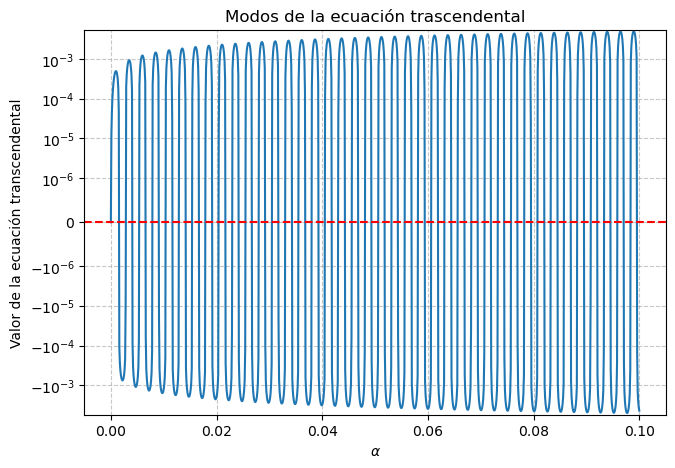

In [5]:
plt.figure(figsize=(7.5,5))
alpha_plot=np.linspace(0.0,0.1,1000)
plt.plot(alpha_plot,robin_eq(alpha_plot))
# plt.legend()
plt.title("Modos de la ecuación trascendental")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\alpha$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/transcendental_radial_tworegion_z'.pdf", bbox_inches='tight')
plt.show()

In [6]:
# Estimar raíces con brentq en intervalos [a, b] con cambio de signo
alpha_min = 0.0
alpha_n = []
step = 0.0001  # Paso inicial para buscar raíces

alpha_current = alpha_min
while len(alpha_n) < n_modes_radial:
    # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
    try:
        root = brentq(robin_eq, alpha_current, alpha_current + step, xtol=1e-6)
        alpha_n.append(root)
        alpha_current = root + step  # Mover el inicio para la próxima búsqueda
    except ValueError:
        alpha_current += step
alpha_n=np.array(alpha_n)

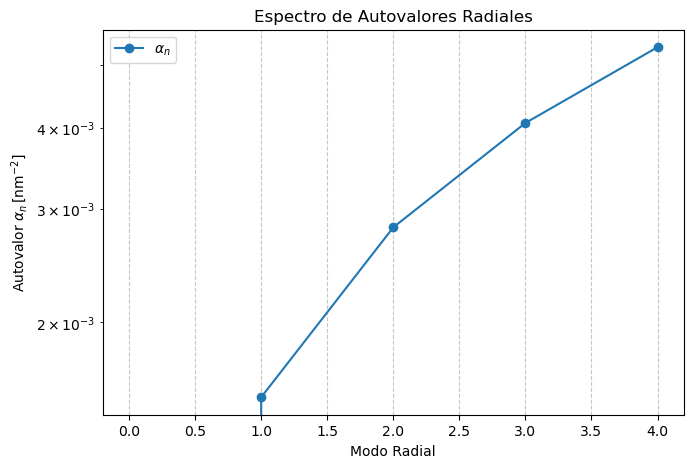

In [7]:
plt.figure(figsize=(7.5, 5))
plt.semilogy(alpha_n, 'o-', label=r"$\alpha_n$")
plt.xlabel('Modo Radial')
plt.ylabel(r'Autovalor $\alpha_n\,[\text{nm}^{-2}]$')
plt.title('Espectro de Autovalores Radiales')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/alpha_n_z'.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [8]:
def R_func(alpha, rho):
    """
    Calcula R_n(rho) = J0(alpha_n * rho) normalizados con la norma analítica
      ∫₀ᴿ J₀²(αₙ ρ) ρ dρ = (R²/2)[J₀²(αₙR) + J₁²(αₙR)].

    Args:
        alpha_n: array de raíces αₙ, shape (n_modes,)
        rho_vals: escalar o array de posiciones radiales, shape (m,)

    Returns:
        R_normed: array (n_modes, m) de los modos normalizados
        norms:    array (n_modes,) con el valor exacto de la norma
    """
   # 1) Aseguramos que alpha_n y rho_vals sean arrays 1D
    alpha_arr = np.atleast_1d(alpha)              # shape (n_modes,)
    rho_arr   = np.atleast_1d(rho)             # shape (m,)

    # 2) Creamos vistas 2D para broadcasting
    alpha = alpha_arr.reshape(-1, 1)                # (n_modes, 1)
    rho   = rho_arr.reshape(1, -1)                  # (1, m)

    # 3) Evaluamos el modo sin normalizar
    R_matrix = sp.jv(0, alpha * rho)                   # (n_modes, m)

    # 4) Calculamos la norma analítica usando alpha_arr (no el escalar viejo)
    J0R = sp.jv(0, alpha_arr * R)                      # (n_modes,)
    J1R = sp.jv(1, alpha_arr * R)                    # (n_modes,)
    norms = 0.5 * R**2 * (J0R**2 + J1R**2)           # (n_modes,)

    # 5) Aseguramos que norms sea un array 1D
    norms = np.atleast_1d(norms)

    # 6) Factor de normalización
    N = 1.0 / np.sqrt(norms)                        # (n_modes,)

    # 7) Aplicamos normalización por filas
    R_normed = N[:, None] * R_matrix                # (n_modes, m)

    return R_normed, np.sqrt(norms)

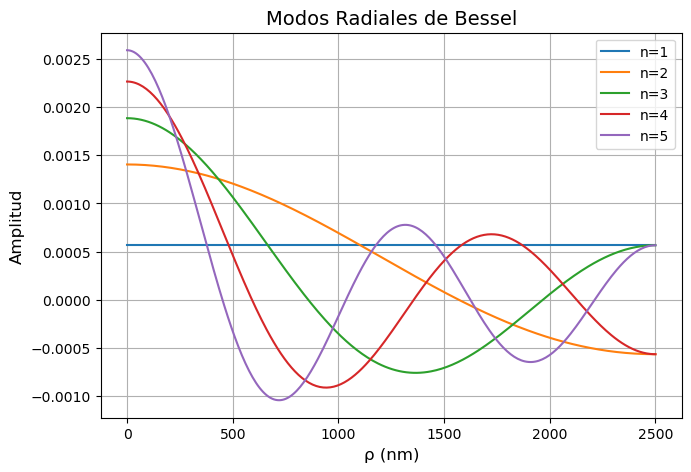

In [9]:
rho_nodes = np.linspace(0.0, R, 300)
R_values,R_norms=R_func(alpha_n,rho_nodes)

# Graficar modos radiales
plt.figure(figsize=(7.5, 5))
for n in range(min(16, n_modes_radial)):
    plt.plot(rho_nodes, R_values[n], label=f"n={n+1}", linewidth=1.5)

plt.xlabel("ρ (nm)", fontsize=12)
plt.ylabel("Amplitud", fontsize=12)
plt.title("Modos Radiales de Bessel", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_radiales_z'.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [10]:
##############################################################################
# 2. Ecuación trascendental
##############################################################################
def transcendental_eq(Lambda, alpha_n):
    beta_1_sq = (Lambda**2 - alpha_n**2 * D1) / D1
    beta_2_sq = (Lambda**2 - alpha_n**2 * D2) / D2
    
    # if beta_1_sq < 0 or beta_2_sq < 0:
    #     return np.inf  # Evitar raíces complejas
    
    beta_1 = np.sqrt(beta_1_sq)
    beta_2 = np.sqrt(beta_2_sq)

    gamma=np.sin(beta_2*(L-z_c))-kappa/D2/beta_2*np.cos(beta_2*(L-z_c))
    theta=np.cos(beta_2*(L-z_c))+kappa/D2/beta_2*np.sin(beta_2*(L-z_c))
    
    # return (D1 * beta_1*np.cos(beta_2*(L-z_c))-kappa*D2*beta_2/D1/beta_1*np.sin(beta_2*(L-z_c))) * np.sin(beta_1 * z_c) + (kappa**beta_1*np.cos(beta_2*(L-z_c))+D2 * beta_2*np.sin(beta_2 * (L - z_c))) * np.cos(beta_1 * z_c)
    return (kappa*theta-D2*beta_2*gamma)*np.cos(beta_1*z_c)-(D1*beta_1*theta+kappa*beta_2*D2/D1/beta_1*gamma)*np.sin(beta_1*z_c)

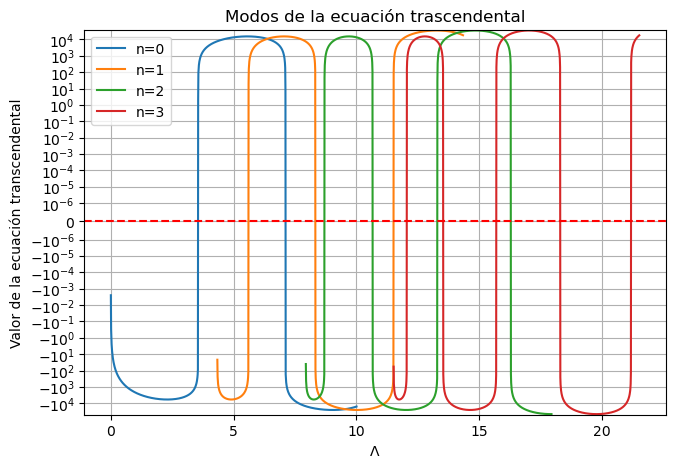

In [11]:
plt.figure(figsize=(7.5,5))
for n in range(4):
    Lambda=np.linspace(alpha_n[n]*np.sqrt(D2)+1e-3,1e1+alpha_n[n]*np.sqrt(D2)+1e-3,1000)
    plt.plot(Lambda,transcendental_eq(Lambda,alpha_n[n]),label=f'n={n}')
plt.legend()
plt.title("Modos de la ecuación trascendental")
plt.ylabel("Valor de la ecuación transcendental")
plt.xlabel(r"$\Lambda$")
plt.axhline(0, color='red', linestyle='--')
plt.yscale('symlog', linthresh=1e-6)
plt.grid(True)
plt.savefig("figuras/transcendental_axial_tworegion_z'.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [12]:
##############################################################################
# 3. Búsqueda de autovalores Λ para un α_n dado
##############################################################################

def find_m_roots(alpha, Lambda_max=5e4):
    Lambda_min = alpha * np.sqrt(D2)+1e-3
    roots = []
    step = 0.01  # Paso inicial para buscar raíces
    
    Lambda_current = Lambda_min
    while len(roots) < m_max:
        # Buscar raíces en el intervalo [Lambda_current, Lambda_current + step]
        try:
            root = brentq(transcendental_eq, Lambda_current, Lambda_current + step,
                           args=(alpha), xtol=1e-6)
            roots.append(root**2)
            Lambda_current = root + step  # Mover el inicio para la próxima búsqueda
        except ValueError:
            Lambda_current += step
    
    return np.array(roots[:m_max])  # Devuelve hasta m_max raíces

eigenvalues_ax = Parallel(n_jobs=4, verbose=1)(delayed(find_m_roots)(alpha) for n, alpha in enumerate(alpha_n))
eigenvalues_ax = np.array(eigenvalues_ax)
# Encontrar raíces para cada αₙ hasta m_max
# eigenvalues_ax = np.zeros((n_modes_radial,m_max))
# for n,alpha in enumerate(alpha_n):
#     eigenvalues_ax[n,:] = axial_results[n]

[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 out of   5 | elapsed:    1.1s finished


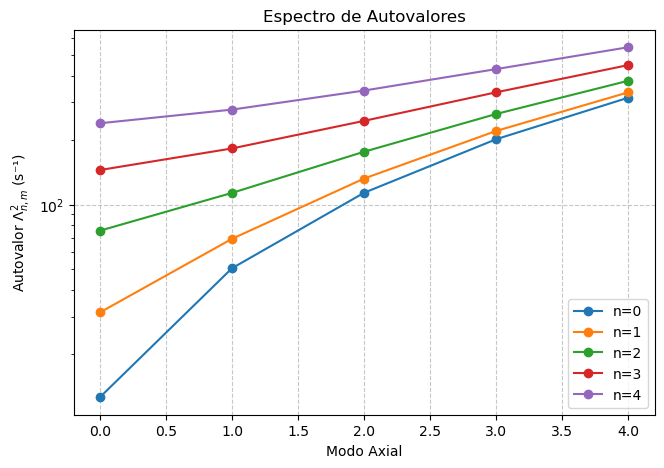

In [13]:
# Graficar espectro de autovalores
plt.figure(figsize=(7.5,5))
for n in range(min(16,n_modes_radial)):
    evals = eigenvalues_ax[n]
    plt.semilogy(evals, 'o-', label=f'n={n}')
plt.xlabel('Modo Axial')
plt.ylabel(r'Autovalor $\Lambda_{n,m}^2$ (s⁻¹)')
plt.title('Espectro de Autovalores')
plt.legend()
plt.grid(ls='--', alpha=0.7)
plt.savefig("figuras/eigenvalues_tworegionz'.pdf", bbox_inches='tight')
plt.show()
plt.close()

In [14]:
##############################################################################
# 4. Z(z) sin coeficientes
##############################################################################
z_nodes=np.linspace(0.0,L,N_z)

# Definir fz_raw vectorizado
def fz_raw(z_val, n, m):
    z = np.array(z_val, dtype=float)
    # modos
    r_mode = alpha_n[n]
    z_mode = eigenvalues_ax[n][m]
    
    beta_1 = np.sqrt((z_mode - r_mode**2 * D1) / D1)
    beta_2 = np.sqrt((z_mode - r_mode**2 * D2) / D2)
    
    # expresiones para cada región
    expr1 = np.cos(beta_1 * (z)) + (kappa / (D1 * beta_1)) * np.sin(beta_1 * (z))
    expr2 = (np.cos(beta_1 * z_c) + (kappa / (D1 * beta_1)) * np.sin(beta_1 * z_c)) * \
            ((np.sin(beta_2*(L-z_c))-kappa*np.cos(beta_2*(L-z_c)))/(np.cos(beta_2*(L-z_c))+kappa*np.sin(beta_2*(L-z_c)))*\
            np.sin(beta_2 * (z - z_c)) + np.cos(beta_2 * (z - z_c)))
    
    # seleccionar por región
    return np.where(z <= z_c, expr1, expr2)

# Cálculo de C_nm vectorizado
C_nm = np.zeros((n_modes_radial, m_max))
for n in range(n_modes_radial):
    for m in range(m_max):
        Z_vals = fz_raw(z_nodes, n, m)
        integral = np.trapz(Z_vals**2, z_nodes)
        C_nm[n, m] = 1.0 / np.sqrt(integral)

# Función normalizada
def fz(z_val, n, m):
    return C_nm[n, m] * fz_raw(z_val, n, m)   

In [15]:
# Para cada modo (n,m) verificar:
z_test = (z_c) * np.ones(100)
left = fz_raw(z_c - 1e-6, n, m)  # Límite izquierdo
right = fz_raw(z_c + 1e-6, n, m) # Límite derecho
assert np.allclose(left, right, atol=1e-4)

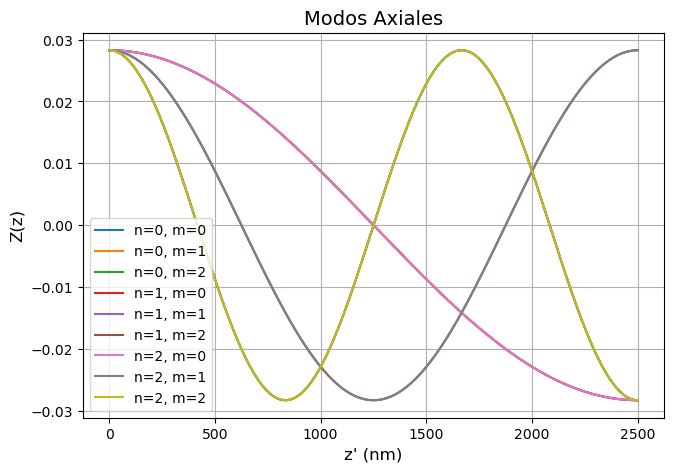

In [16]:
plt.figure(figsize=(7.5,5))
for n in range(3):
    for m in range(3):
        Zs=[]
        for z_val in z_nodes:
            Zs.append(fz(z_val,n,m))
        plt.plot(z_nodes,np.array(Zs), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("z' (nm)", fontsize=12)
plt.ylabel("Z(z)", fontsize=12)
plt.title("Modos Axiales", fontsize=14)
plt.legend()
plt.grid(True)
plt.savefig("figuras/modos_axiales_tworegion_z'.pdf", bbox_inches="tight")
plt.show()
plt.close() 

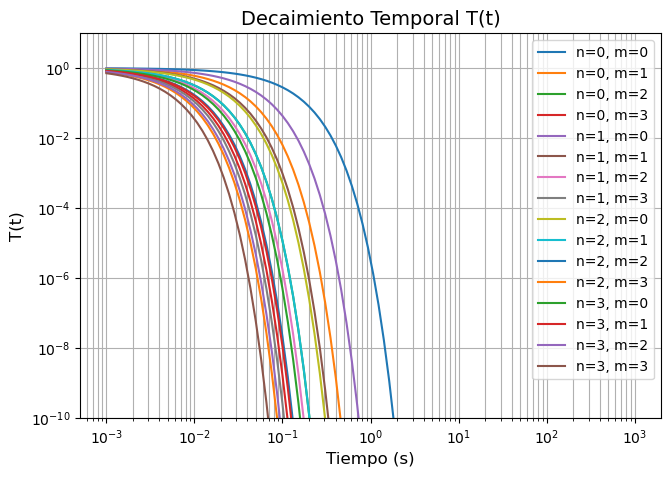

In [17]:
##############################################################################
# 5. Término Temporal T(t)
##############################################################################
# Ahora, para cada eigenvalor (de la parte axial) usaremos el valor absoluto
# para que T(t)=exp(-|λ| t) decaiga.
def T(t, lam):
    return np.exp(-lam * t)

# Graficamos T(t) para los modos del sistema axial
plt.figure(figsize=(7.5,5))
t_plot = np.logspace(-3, 3, 100)
for n in range(min(4,n_modes_radial)):
    for m in range(min(4, m_max)):
        lam = eigenvalues_ax[n,m]
        plt.loglog(t_plot, T(t_plot, lam), label=f"n={n}, m={m}", linewidth=1.5)
plt.xlabel("Tiempo (s)", fontsize=12)
plt.ylabel("T(t)", fontsize=12)
plt.ylim(1e-10,1e1)
plt.title("Decaimiento Temporal T(t)", fontsize=14)
plt.legend()
plt.grid(True, which="both")
plt.savefig("figuras/T_t_tworegionz'.pdf", bbox_inches="tight")
plt.show()
plt.close()

In [18]:
##############################################################################
# 6. Cálculo de Coeficientes A_{nm}
##############################################################################
# Se asume que la condición inicial es:
#     P(ρ, z, 0) ∝ δ(ρ-ρ0) δ(z-z0) / (2πρ0)
# Con ρ0 = 750 nm y z0 = 10 nm.
# --- Parámetros de la delta ---
rho0, z0 = 0.0,  0.0  # centro (nm)

# --- 1) Mallado de cuadratura cilíndrica (ρ, z) ---
N_quad = 1000
rho_quad = np.linspace(0.0, R, N_quad)   # nodos radiales
z_quad   = np.linspace(0.0, L, N_quad)   # nodos axiales

# (1) Evaluar modos radiales en rho0:
#     R_func(alpha_n, x) devuelve R_mat[n,i] = R_n(x)
#     Usamos un punto x = rho0
a0 = np.array([rho0])                       # array de un punto
R0, _ = R_func(alpha_n, a0)                # R0.shape = (n_modes_radial, 1)
R0 = R0[:, 0]                              # ahora vector (n_modes_radial,)

# (2) Evaluar modos axiales en z0
def eval_Z_at(z_val):
    Z0 = np.empty((n_modes_radial, m_max))
    for n in range(n_modes_radial):
        for m in range(m_max):
            Z0[n, m] = fz(z0,n,m)
    return Z0

Z0 = eval_Z_at(z0)  # Z0.shape = (n_modes_radial, m_max)

# (4) Coeficientes modal A_nm: producto de R0 y Z0
#     A_nm_delta[n,m] = R_n(rho0) * Z_{n,m}(z0)
A_nm = R0[:, None] * Z0            # shape (n_modes_radial, m_max)
print(f"A_nm_delta shape: {A_nm.shape}")

A_nm_delta shape: (5, 5)


In [19]:
##############################################################################
## # 7. Densidad de Probabilidad P(ρ,z,t)
##############################################################################
rho_nodes = np.linspace(0.0, R, 1000)
z_nodes = np.linspace(0.0, L, 1000)

# Precompute Bessel J0 for all radial modes and rho
# J0_mat shape: (n_modes, Nr)
R0_mat,_ = R_func(alpha_n, rho_nodes)

# Precompute axial modes Z_tens: shape (Nz, n_modes, m_max)
Nz = len(z_nodes)
n_modes, m_max = eigenvalues_ax.shape
Z_tens = np.zeros((Nz, n_modes, m_max))
for n in range(n_modes):
    for m in range(m_max):
        Z_tens[:, n, m] = fz(z_nodes, n, m)

In [20]:
def compute_P_vec(t):
    """
    Vectorized computation of P(rho, z, t).
    
    Parameters:
    - t:        scalar time

    Returns:
    - P: 2D array of shape (Nz, Nr)
    """
    
    # Temporal decay T: shape (n_modes, m_max)
    T_decay = np.exp(-eigenvalues_ax * t)
    # Combine coefficients with normalization and decay: shape (n_modes, m_max)
    W = A_nm * T_decay
    
    # Sum over axial modes m → B shape (Nz, n_modes)
    B = np.sum(Z_tens * W[None, :, :], axis=2)
    
    # Combine with radial modes → S shape (Nr, Nz)
    # J0_mat.T: (Nr, n_modes), B.T: (n_modes, Nz)
    S = np.dot(R0_mat.T, B.T)
    
    # Return absolute value, shaped back to (Nz, Nr)
    return np.maximum(S.T,0)

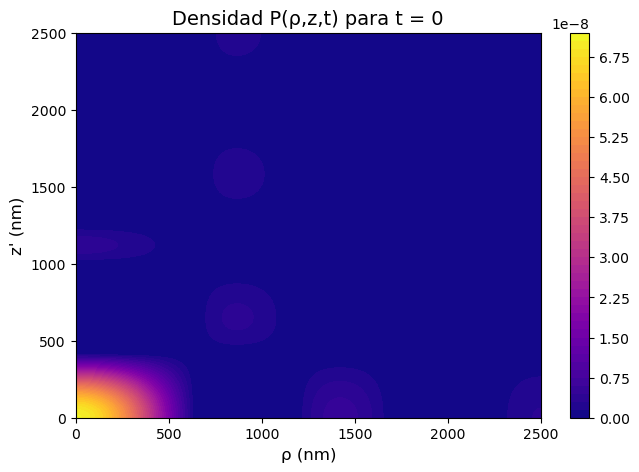

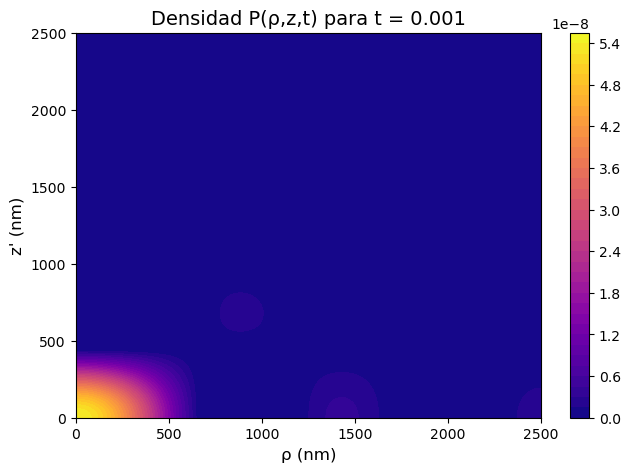

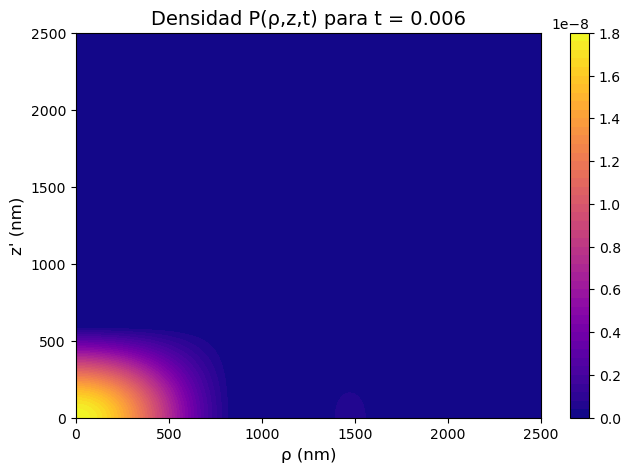

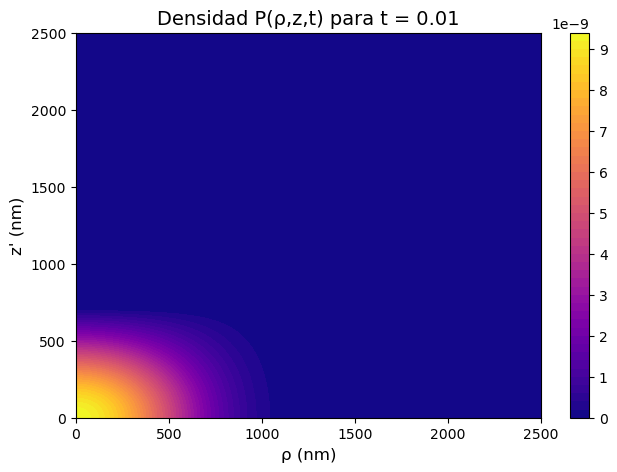

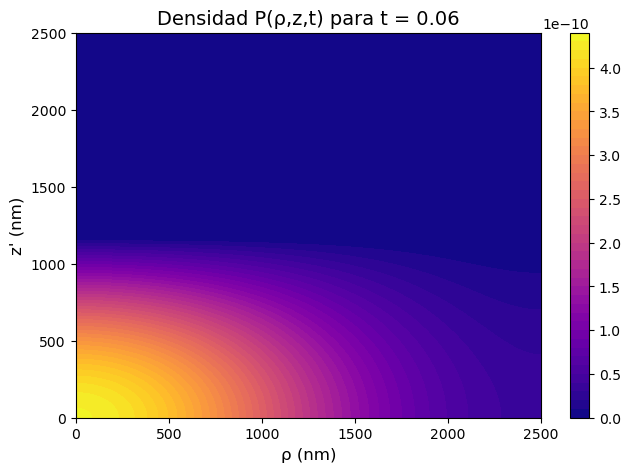

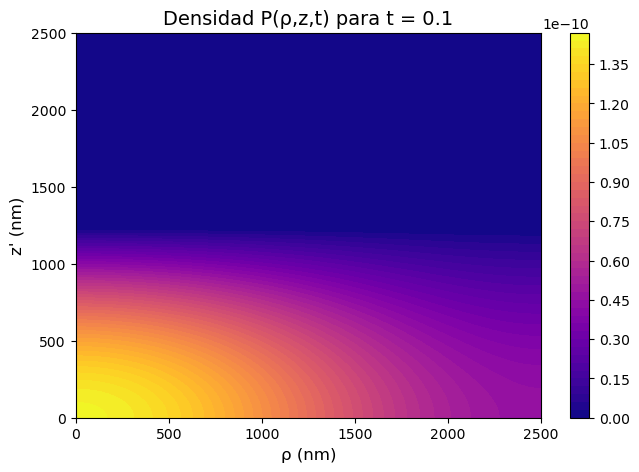

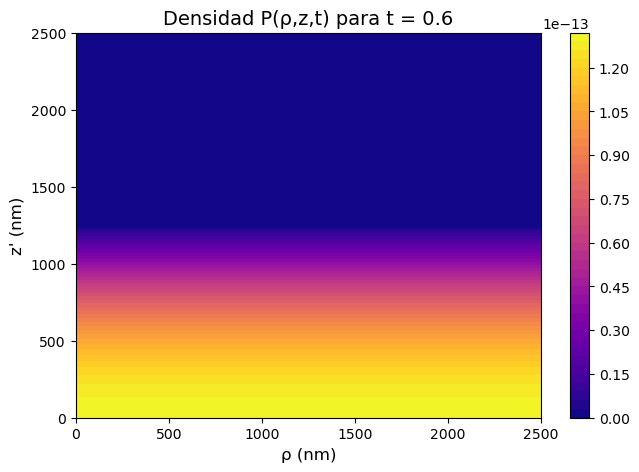

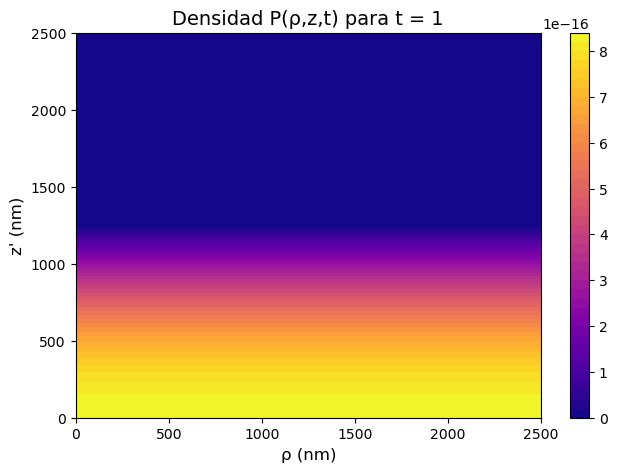

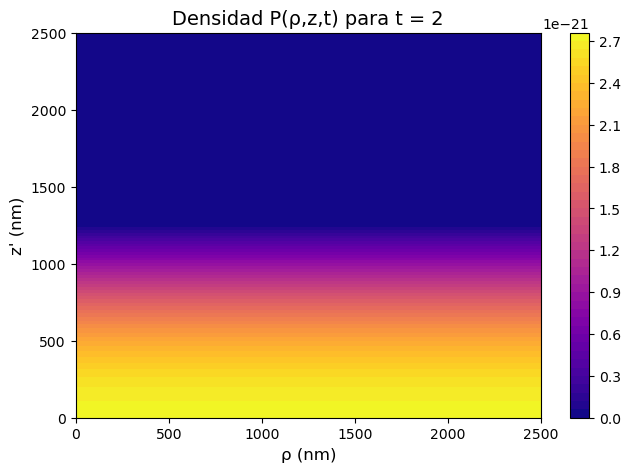

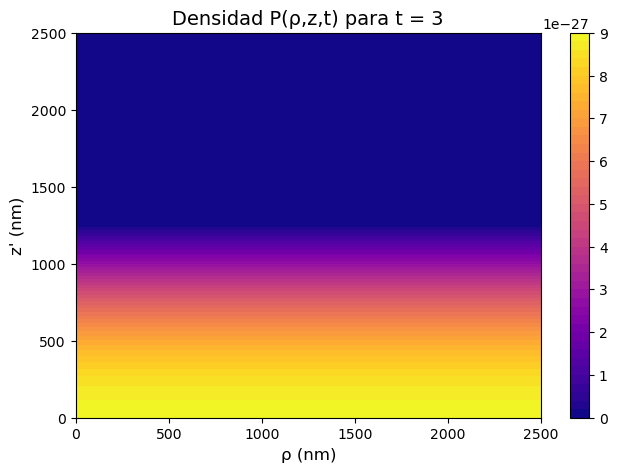

In [21]:
for t_val in [0,1e-3,6e-3,1e-2,6e-2,1e-1,6e-1,1,2,3]:
    P_val = compute_P_vec(t_val)
    
    plt.figure(figsize=(7.5,5))
    plt.contourf(rho_nodes, z_nodes, P_val, 50, cmap="plasma")
    plt.xlabel("ρ (nm)", fontsize=12)
    plt.ylabel("z' (nm)", fontsize=12)
    plt.title(f"Densidad P(ρ,z,t) para t = {t_val}", fontsize=14)
    plt.colorbar()
    plt.savefig(f"figuras/P_contour_tworegion_z'_{t_val}.pdf", bbox_inches="tight")
    plt.show()
    plt.close()

In [22]:
##############################################################################
# 8. Función de Correlación G(t)
##############################################################################

dr = rho_nodes[1] - rho_nodes[0]
dz = z_nodes[1] - z_nodes[0]

# Precomputar factor dipolar
R2 = rho_nodes**2
Z2 = (z_nodes + d)**2
f_mat = (3*Z2[None, :] - R2[:, None]) / (R2[:, None] + Z2[None, :])**2.5
f0 = (3*(z0 + d)**2 - rho0**2) / ((z0 + d)**2 + rho0**2)**2.5
rho_factor = (rho_nodes[:, None] * f0 * f_mat * dr * dz)

In [23]:
t_values = np.logspace(-7, 1, N_quad)
tau_values=D_eff*t_values/d**2
G_values = np.zeros_like(t_values)
for i,t_val in enumerate(t_values):
    S=compute_P_vec(t_val).T
    integrand = rho_factor * S  # (Nr, Nz) * (Nr, Nz)
    
    G_values[i] = (5/(16*np.pi)) * np.sum(integrand)

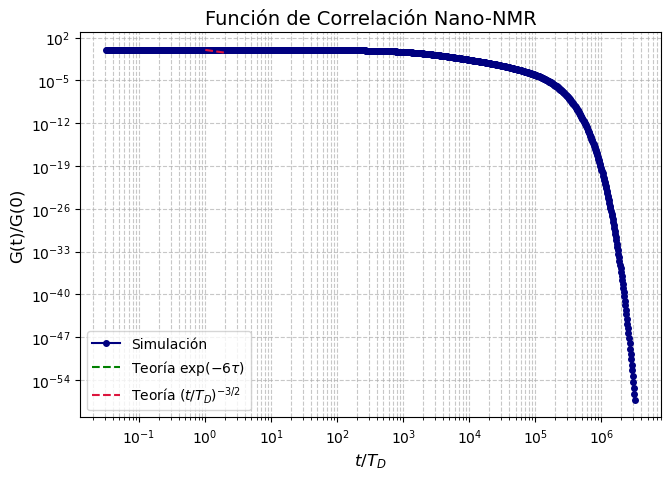

In [24]:
np.savetxt("data/G_vs_t_tworegion_z'.dat", np.c_[t_values, G_values], header="Tiempo(s) G(t)", fmt="%.9e")

plt.figure(figsize=(7.5,5))
plt.loglog(tau_values, G_values/G_values[0], "o-", label="Simulación", color="navy", markersize=4, linewidth=1.5)
plt.plot(tau_values[tau_values<0.01], np.exp(-6*tau_values[tau_values<0.01]), "--", label=r"Teoría $\exp(-6\tau)$", color="green", linewidth=1.5)
plt.plot(tau_values[(tau_values>=1)&(tau_values<=2)], (tau_values[(tau_values>=1)&(tau_values<=2)])**-1.5, "--", label=r"Teoría $(t/T_D)^{-3/2}$", color="crimson", linewidth=1.5)
# plt.xlabel("Tiempo (s)", fontsize=12)
plt.xlabel(r"$t/T_D$", fontsize=12)
plt.ylabel("G(t)/G(0)", fontsize=12)
plt.title("Función de Correlación Nano-NMR", fontsize=14)
plt.legend()
plt.grid(which="both", ls='--', alpha=0.7)
plt.savefig("figuras/correlacion_nanoNMR_tworegion_z'.pdf", bbox_inches="tight", dpi=300)
plt.show()
plt.close()